# E-RayZer on the bundled examples

Runs the pretrained E-RayZer checkpoints from the team folder on the example scenes
in `E-RayZer/examples` and shows what the model produces:

1. predicted cameras and intrinsics,
2. renders vs. inputs (PSNR), per-pixel depth / opacity / scale of the Gaussians,
3. an **interactive Gaussian splat viewer** (WebGL, runs in the output cell),
4. gsplat renders along a new camera path, plus `.ply` / `.html` export,
5. a held-out test (5 input views → 5 unseen views) and a summary over all examples.

**Requirements:** a GPU with compute capability ≥ 8.0 (RTX 30xx / A5000 / 4090 / H200, partition `24g`),
because the transformer runs in bf16 through xformers. Run the kernel inside the project image
(`/mnt/projects/p3dcv/anycam/envs/p3dcv.sqsh`); it needs `ipykernel` in addition to the image's packages.

Outputs (images, the viewer) make the notebook large — clear them before committing.

In [1]:
import os, sys, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from einops import rearrange
from IPython.display import Video, display, HTML

# repository root = the folder that contains erayzer_core
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erayzer_core").is_dir())
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / "notebooks"))

from app_core.engine import ERayZerEngine
from erayzer_core.model.gaussians_renderer import render_opencv_cam_gsplat
import gs_viewer

PRETRAINED_DIR = Path("/mnt/projects/p3dcv/anycam/checkpoints/pretrained")
CKPT = PRETRAINED_DIR / "erayzer_multi.pt"          # or "erayzer_dl3dv.pt"
CONFIG = REPO_ROOT / "config" / "erayzer_inference.yaml"
EXAMPLES_DIR = REPO_ROOT.parent / "E-RayZer" / "examples"   # P3DCV does not ship the example images
OUT_DIR = Path.home() / "runs" / "notebook_examples"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("repo     ", REPO_ROOT)
print("ckpt     ", CKPT, f"({CKPT.stat().st_size / 1e9:.1f} GB)")
print("examples ", EXAMPLES_DIR)
print("outputs  ", OUT_DIR)

repo      /mnt/home/colinmarmond/code/P3DCV
ckpt      /mnt/projects/p3dcv/anycam/checkpoints/pretrained/erayzer_multi.pt (3.0 GB)
examples  /mnt/home/colinmarmond/code/E-RayZer/examples
outputs   /mnt/home/colinmarmond/runs/notebook_examples


In [2]:
assert torch.cuda.is_available(), "No GPU visible. Run this notebook on a GPU node."
cc = torch.cuda.get_device_capability()
print(torch.cuda.get_device_name(), "compute capability", cc)
assert cc >= (8, 0), (
    "E-RayZer runs its attention in bf16 via xformers, which needs compute capability >= 8.0 "
    "(RTX 30xx/A5000/4090/H200: partition 24g, --gres=gpu:1,ccc:86)."
)

NVIDIA GeForce RTX 3090 compute capability (8, 6)


## Load the model
Loading prints `Unexpected keys: 32` — weights in the file that the released code does not use (expected).

In [3]:
engine = ERayZerEngine(str(CONFIG), str(CKPT), "cuda:0", str(OUT_DIR))
model, device = engine.model, engine.device
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters, image size {engine.image_size}, "
      f"amp {engine.amp_dtype if engine.amp_enabled else 'off'}")

[ERayZerEngine] Unexpected keys: 32
[ERayZerEngine] Model loaded successfully.
246 M parameters, image size 256, amp torch.bfloat16


## The examples

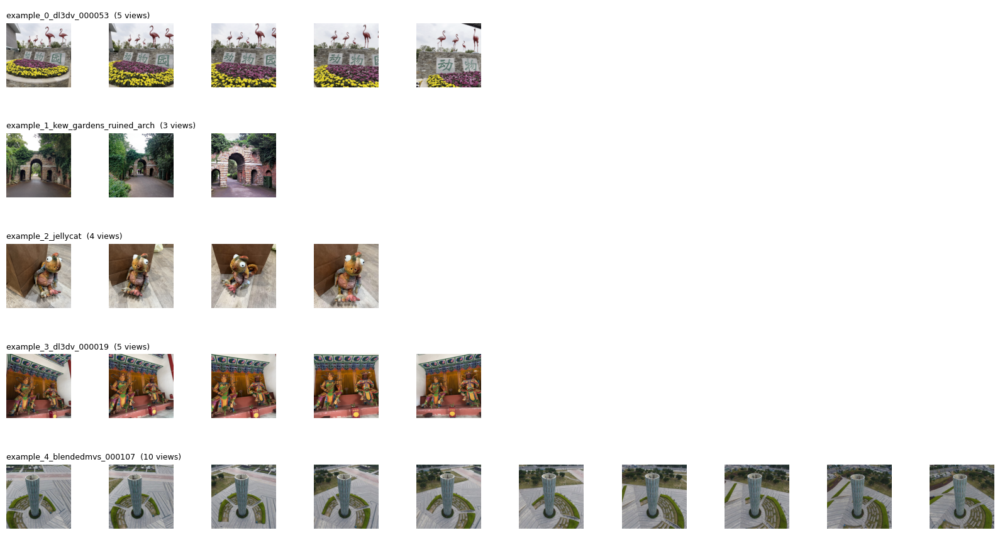

In [4]:
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".webp"}

def example_files(name, max_views=10):
    files = sorted(p for p in (EXAMPLES_DIR / name).iterdir() if p.suffix.lower() in IMAGE_EXTS)
    if len(files) > max_views:   # evenly spaced, like scripts/infer.py
        step = (len(files) - 1) / (max_views - 1)
        files = [files[round(i * step)] for i in range(max_views)]
    return [str(f) for f in files]

EXAMPLES = sorted(p.name for p in EXAMPLES_DIR.iterdir() if p.is_dir())
fig, axes = plt.subplots(len(EXAMPLES), 10, figsize=(16, 1.8 * len(EXAMPLES)))
for r, name in enumerate(EXAMPLES):
    batch = engine._prepare_batch(example_files(name))      # centre crop + resize, as the model sees them
    for c in range(10):
        ax = axes[r, c]; ax.axis("off")
        if c < batch["image"].shape[1]:
            ax.imshow(batch["image"][0, c].permute(1, 2, 0))
    axes[r, 0].set_title(f"{name}  ({batch['num_real_views']} views)", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## Helpers

`run_model` calls the model directly (instead of `engine.run`) so that the raw output — Gaussians, cameras,
intrinsics — stays available. `analyse` turns it into numpy arrays.

* **Inference mode** (default, what the demo does): every real view is an input and is also rendered back,
  so the PSNR measures reconstruction of the inputs, not novel views. With fewer than 10 views the model pads
  by repeating the last image; with fewer than 5 inputs the padded copies are also used as inputs.
* **Held-out mode** (`holdout=True`, needs exactly 10 views): the evaluation split, inputs 0, 2, 4, 6, 9 and
  targets 1, 3, 5, 7, 8. The poses of all 10 views are still estimated from all 10 images (E-RayZer's protocol),
  but the Gaussians come from the 5 inputs only.

In [5]:
def run_model(files, holdout=False):
    cfg = engine.config            # the model holds the same config object
    if holdout:
        assert len(files) == 10, "held-out mode needs exactly 10 views"
    cfg.inference, cfg.evaluation = (not holdout), holdout
    try:
        batch = engine._prepare_batch(files)
        batch_gpu = engine._move_to_device(batch)
        torch.cuda.synchronize(); t0 = time.time()
        with torch.no_grad(), torch.autocast("cuda", dtype=engine.amp_dtype, enabled=engine.amp_enabled):
            result = model(batch_gpu)
        torch.cuda.synchronize(); dt = time.time() - t0
    finally:
        cfg.inference, cfg.evaluation = True, False
    return batch, result, dt


def psnr(a, b):
    return float(-10 * torch.log10(((a.float() - b.float()) ** 2).mean().clamp_min(1e-10)))


def analyse(batch, result):
    """Everything the plots and the viewer need, as numpy arrays."""
    v_real = int(batch["num_real_views"])
    input_idx = result.input_idx[0].cpu().numpy()
    v_in = len(input_idx)
    gm = result.gaussians[0]                           # GaussianModel, float32, on the GPU
    H = W = engine.image_size
    to_grid = lambda t: rearrange(t, "(v hh ww ph pw) c -> v c (hh ph) (ww pw)",
                                  v=v_in, hh=model.hh, ww=model.ww, ph=model.ph, pw=model.pw)

    c2w_in = result.c2w_input[0].float()
    xyz_grid = to_grid(gm.get_xyz)                    # [v_in, 3, H, W], one Gaussian per input pixel
    # depth = distance along each camera's optical axis (z in camera coordinates)
    depth = torch.einsum("vchw,vc->vhw", xyz_grid - c2w_in[:, :3, 3, None, None], c2w_in[:, :3, 2])

    n_per_view = H * W * (model.config.model.gs_per_pixel_sqrt ** 2)
    view_of_gaussian = np.arange(gm.get_xyz.shape[0]) // n_per_view          # index into input_idx
    real_input = input_idx < v_real                                          # padded copies are not real views

    return dict(
        v_real=v_real, input_idx=input_idx, real_input=real_input, gm=gm,
        c2w=result.c2w[0, :v_real].float().cpu().numpy(),                   # all real views, OpenCV c2w
        fxfycxcy=result.fxfycxcy[:v_real].float().cpu().numpy(),            # normalised by image size
        depth=depth.cpu().numpy(),
        opacity=to_grid(gm.get_opacity)[:, 0].cpu().numpy(),
        scale=to_grid(gm.get_scaling).mean(1).cpu().numpy(),
        xyz=gm.get_xyz.cpu().numpy(),
        sh=gm.get_features.cpu().numpy(),                                   # [N, 16, 3]
        opac_flat=gm.get_opacity[:, 0].cpu().numpy(),
        scale_flat=gm.get_scaling.cpu().numpy(),
        quat=gm.get_rotation.cpu().numpy(),                                 # (w, x, y, z)
        view_of_gaussian=input_idx[view_of_gaussian],                        # original view index per Gaussian
        keep=real_input[view_of_gaussian],
    )


def show_video(frames, path, fps=24):
    """frames: [F, 3, H, W] tensor in 0..1"""
    import imageio.v2 as imageio
    arr = (frames.clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy() * 255).round().astype(np.uint8)
    imageio.mimwrite(path, arr, fps=fps, codec="libx264")
    display(Video(str(path), embed=True, width=384, html_attributes="controls loop autoplay muted"))

## Run one example

In [6]:
EXAMPLE = "example_0_dl3dv_000053"     # pick any name from EXAMPLES
files = example_files(EXAMPLE)
batch, result, dt = run_model(files)
A = analyse(batch, result)
run_dir = OUT_DIR / EXAMPLE
run_dir.mkdir(parents=True, exist_ok=True)

print(f"{EXAMPLE}: {A['v_real']} views, forward pass {dt:.2f} s, "
      f"{A['xyz'].shape[0]:,} Gaussians from {len(A['input_idx'])} input views {A['input_idx'].tolist()}")
print("\npredicted intrinsics (pixels at 256 x 256) and horizontal FOV:")
for i, (fx, fy, cx, cy) in enumerate(A["fxfycxcy"] * engine.image_size):
    fov = np.degrees(2 * np.arctan(engine.image_size / (2 * fx)))
    print(f"  view {i}: fx {fx:6.1f}  fy {fy:6.1f}  cx {cx:6.1f}  cy {cy:6.1f}   FOV {fov:5.1f} deg")

/mnt/home/colinmarmond/code/P3DCV/erayzer_core/utils/camera_utils.py:278: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(traj, dtype=torch.float32), torch.tensor(k_interp, dtype=torch.float32)


example_0_dl3dv_000053: 5 views, forward pass 0.83 s, 327,680 Gaussians from 5 input views [0, 1, 2, 3, 4]

predicted intrinsics (pixels at 256 x 256) and horizontal FOV:
  view 0: fx  222.0  fy  222.0  cx  128.0  cy  128.0   FOV  59.9 deg
  view 1: fx  222.0  fy  222.0  cx  128.0  cy  128.0   FOV  59.9 deg
  view 2: fx  222.0  fy  222.0  cx  128.0  cy  128.0   FOV  59.9 deg
  view 3: fx  222.0  fy  222.0  cx  128.0  cy  128.0   FOV  59.9 deg
  view 4: fx  222.0  fy  222.0  cx  128.0  cy  128.0   FOV  59.9 deg


### Inputs, renders and error
The renders come from the model's own gsplat pass (with full SH).

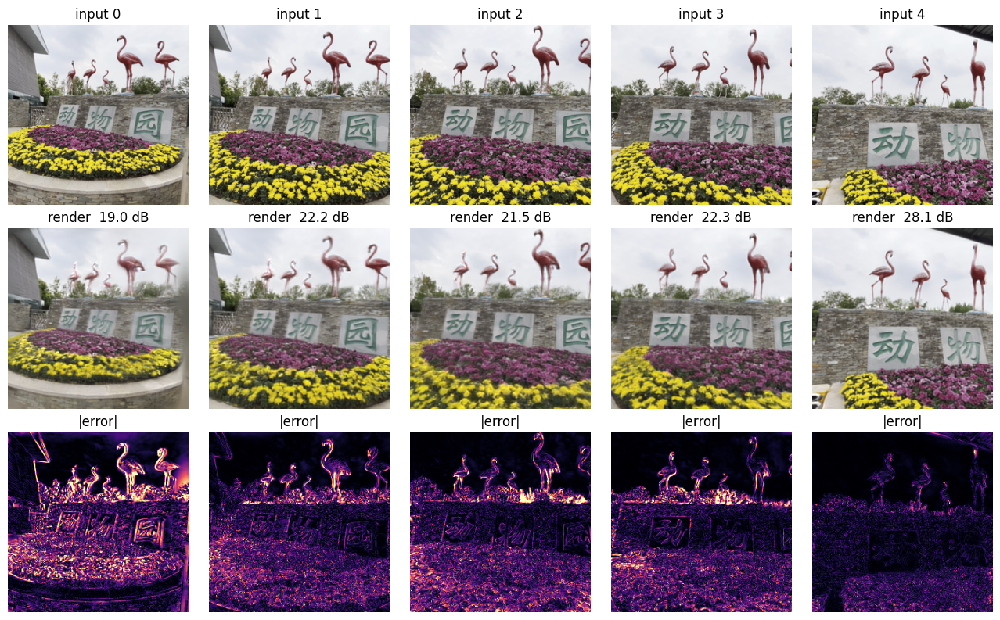

mean PSNR over the inputs: 22.60 dB


In [7]:
gt = batch["image"][0]                         # [v, 3, H, W]
render = result.render[0].float().cpu()        # rendered target views = all real views in inference mode
v = A["v_real"]
fig, axes = plt.subplots(3, v, figsize=(2.6 * v, 8), squeeze=False)
for i in range(v):
    err = (render[i] - gt[i]).abs().mean(0)
    axes[0, i].imshow(gt[i].permute(1, 2, 0)); axes[0, i].set_title(f"input {i}")
    axes[1, i].imshow(render[i].clamp(0, 1).permute(1, 2, 0)); axes[1, i].set_title(f"render  {psnr(render[i], gt[i]):.1f} dB")
    axes[2, i].imshow(err, cmap="magma", vmin=0, vmax=0.3); axes[2, i].set_title("|error|")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"mean PSNR over the inputs: {np.mean([psnr(render[i], gt[i]) for i in range(v)]):.2f} dB")

### What the Gaussians look like per pixel
E-RayZer predicts one Gaussian per input pixel, placed along that pixel's ray. Rows: depth along the ray
(camera z), opacity, mean scale (log). Low opacity = the model does not use that pixel's Gaussian much.

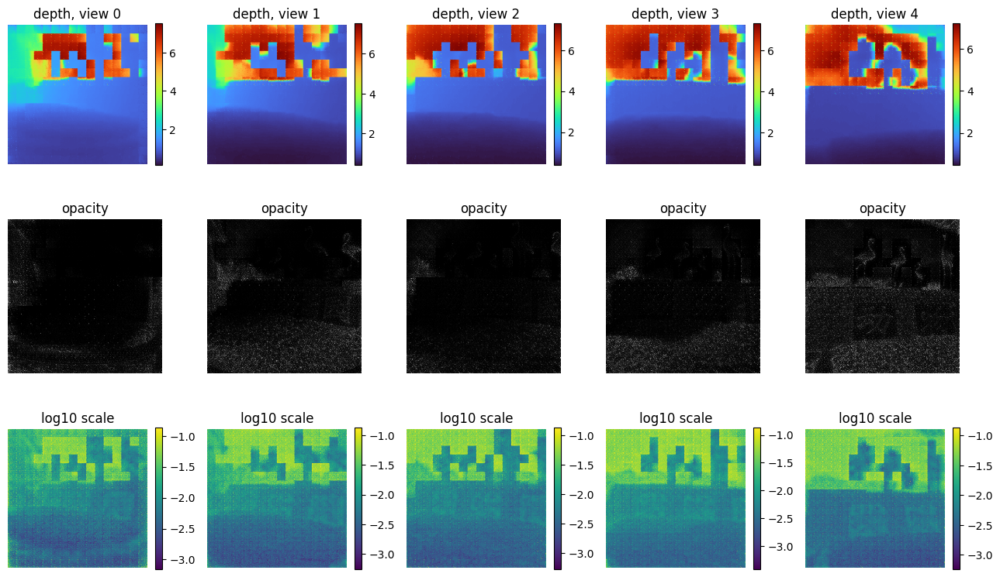

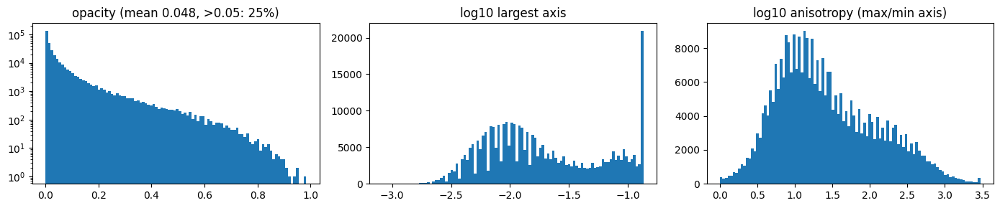

In [8]:
real = np.flatnonzero(A["real_input"])
fig, axes = plt.subplots(3, len(real), figsize=(2.6 * len(real), 8), squeeze=False)
for c, k in enumerate(real):
    im0 = axes[0, c].imshow(A["depth"][k], cmap="turbo"); axes[0, c].set_title(f"depth, view {A['input_idx'][k]}")
    plt.colorbar(im0, ax=axes[0, c], fraction=0.046)
    im1 = axes[1, c].imshow(A["opacity"][k], cmap="gray", vmin=0, vmax=1); axes[1, c].set_title("opacity")
    im2 = axes[2, c].imshow(np.log10(A["scale"][k]), cmap="viridis"); axes[2, c].set_title("log10 scale")
    plt.colorbar(im2, ax=axes[2, c], fraction=0.046)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
o, s = A["opac_flat"][A["keep"]], A["scale_flat"][A["keep"]]
axes[0].hist(o, bins=100); axes[0].set_yscale("log"); axes[0].set_title(f"opacity (mean {o.mean():.3f}, >0.05: {(o > 0.05).mean():.0%})")
axes[1].hist(np.log10(s.max(1)), bins=100); axes[1].set_title("log10 largest axis")
axes[2].hist(np.log10(s.max(1) / s.min(1)), bins=100); axes[2].set_title("log10 anisotropy (max/min axis)")
plt.tight_layout(); plt.show()

### Predicted cameras and point cloud (static)

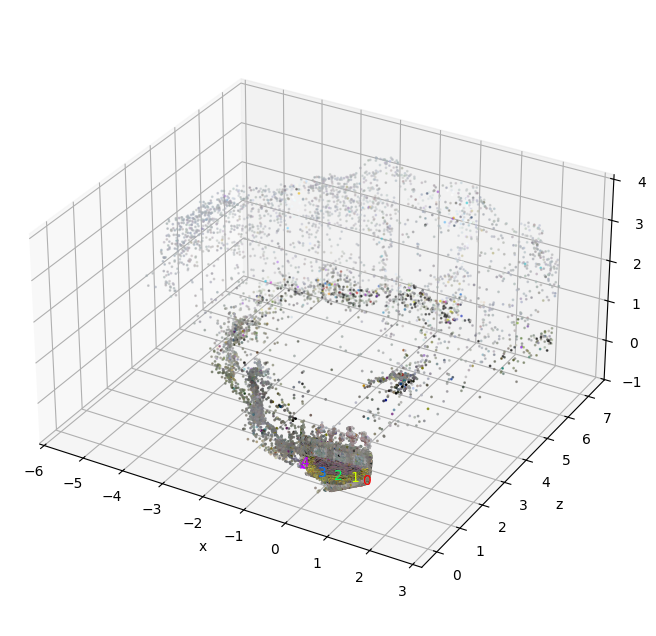

camera centres:
 [[ 1.406  0.031  0.083]
 [ 1.164  0.025  0.045]
 [ 0.812  0.03  -0.025]
 [ 0.477  0.024 -0.106]
 [ 0.    -0.     0.   ]]


In [9]:
def plot_scene(A, n_points=20000, ax=None):
    keep = np.flatnonzero(A["keep"] & (A["opac_flat"] > 0.05))
    keep = np.random.default_rng(0).choice(keep, min(n_points, keep.size), replace=False)
    rgb = np.clip(0.5 + gs_viewer.SH_C0 * A["sh"][keep, 0], 0, 1)
    ax = ax or plt.figure(figsize=(8, 8)).add_subplot(projection="3d")
    P = A["xyz"][keep]
    ax.scatter(P[:, 0], P[:, 2], -P[:, 1], c=rgb, s=1)            # plot with -y up
    palette = gs_viewer.view_palette(len(A["c2w"]))
    size = 0.1 * np.median(A["depth"])
    for i, (c2w, (fx, fy, cx, cy)) in enumerate(zip(A["c2w"], A["fxfycxcy"])):
        t = c2w[:3, 3]
        corners = [t + c2w[:3, :3] @ (np.array([(u - cx) / fx, (w - cy) / fy, 1.0]) * size) for u, w in ((0, 0), (1, 0), (1, 1), (0, 1))]
        for a, b in [(t, c) for c in corners] + [(corners[k], corners[(k + 1) % 4]) for k in range(4)]:
            ax.plot([a[0], b[0]], [a[2], b[2]], [-a[1], -b[1]], color=palette[i])
        ax.text(t[0], t[2], -t[1], str(i), color=palette[i])
    ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_zlabel("-y")
    ax.set_box_aspect(np.ptp(np.concatenate([P, A["c2w"][:, :3, 3]]), axis=0)[[0, 2, 1]])
    return ax

plot_scene(A); plt.show()
centers = A["c2w"][:, :3, 3]
print("camera centres:\n", np.round(centers, 3))

### The model's own interpolated video

In [10]:
show_video(result.render_video[0], run_dir / "model_render_video.mp4")

## Interactive Gaussian splat viewer

Renders the predicted Gaussians in the output cell with WebGL2 (EWA splatting, back-to-front blending,
full degree-3 SH colours for the current eye position, as gsplat does).

* **Left drag** orbits, **right / shift drag** pans, **wheel** zooms, **W/A/S/D/Q/E** fly (click the canvas first).
* The **view buttons** (or keys 1–9) jump exactly to a predicted camera; the coloured frusta are the predicted cameras.
* **Colour by source view** shows which input view produced which Gaussians — good for seeing where views
  disagree (ghosting, layered surfaces).
* **Min opacity** hides faint Gaussians; **splat scale** shrinks them to show the structure.

The page is also saved as a standalone `.html` (open it in a browser, e.g. after `scp`).
`MAX_SPLATS` keeps the most opaque Gaussians, which limits the output size (~85 bytes per splat).

In [11]:
MAX_SPLATS = 100_000   # ~11 MB per viewer; raise for more detail
keep = A["keep"]
packed = gs_viewer.pack_splats(
    A["xyz"][keep], A["sh"][keep], A["opac_flat"][keep], A["scale_flat"][keep], A["quat"][keep],
    view_ids=A["view_of_gaussian"][keep], num_views=A["v_real"],
    min_opacity=0.02, max_splats=MAX_SPLATS,
)
# per camera: median depth of its Gaussians (orbit distance); views that are not inputs get the overall median
med = {int(A["input_idx"][k]): float(np.median(A["depth"][k])) for k in np.flatnonzero(A["real_input"])}
cam_depths = [med.get(i, float(np.median(list(med.values())))) for i in range(A["v_real"])]
up = -A["c2w"][:, :3, 1].mean(0)

print(f"{len(packed['splats']):,} of {int(keep.sum()):,} Gaussians shown")
gs_viewer.show(packed, A["c2w"], A["fxfycxcy"], cam_depths, up=up, title=EXAMPLE,
               save_to=run_dir / "gs_viewer.html")
print("standalone viewer:", run_dir / "gs_viewer.html")

100,000 of 327,680 Gaussians shown


standalone viewer: /mnt/home/colinmarmond/runs/notebook_examples/example_0_dl3dv_000053/gs_viewer.html


## gsplat renders along a new camera path

The viewer is an approximation of gsplat; this renders with the model's actual rasteriser
(`render_opencv_cam_gsplat`, SH degree 3) on a swing around the scene, starting from a predicted camera.
Moving away from the input cameras shows how much 3D structure the model really recovered.

gsplat at predicted cameras vs model render: max abs diff 0.0000


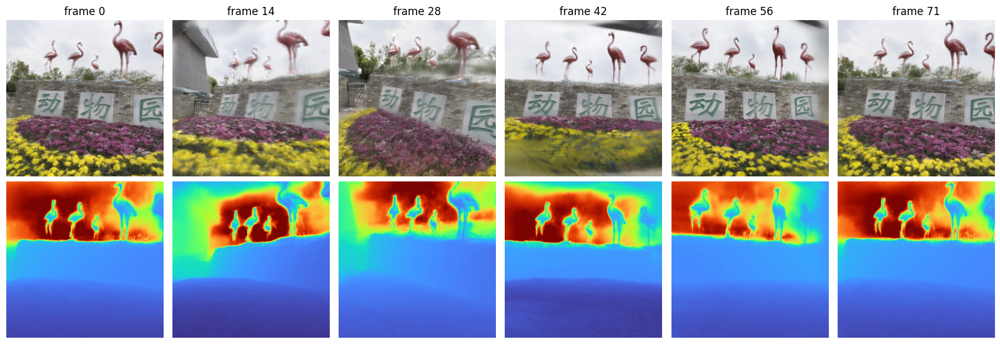

In [12]:
from scipy.spatial.transform import Rotation

def swing_path(c2w, target, up, n=72, yaw_deg=30.0, pitch_deg=10.0):
    out = []
    for t in np.linspace(0, 1, n, endpoint=False):
        R1 = Rotation.from_rotvec(up * np.radians(yaw_deg) * np.sin(2 * np.pi * t)).as_matrix()
        R2 = Rotation.from_rotvec((R1 @ c2w[:3, 0]) * np.radians(pitch_deg) * np.sin(4 * np.pi * t)).as_matrix()
        R = R2 @ R1
        m = np.eye(4); m[:3, :3] = R @ c2w[:3, :3]; m[:3, 3] = target + R @ (c2w[:3, 3] - target)
        out.append(m)
    return np.stack(out)

@torch.no_grad()
def gsplat_render(gm, c2ws, fxfycxcy, size=256, bg=(1.0, 1.0, 1.0), chunk=8):
    rgbs, depths = [], []
    for s in range(0, len(c2ws), chunk):
        C = torch.as_tensor(c2ws[s:s + chunk], dtype=torch.float32, device=device)
        K = torch.as_tensor(fxfycxcy[s:s + chunk], dtype=torch.float32, device=device) * size
        out = render_opencv_cam_gsplat(gm, size, size, C, K, sh_degree=model.config.model.gaussians.sh_degree,
                                       near_plane=model.config.model.near_plane, bg_color=bg, render_depth=True)
        rgbs.append(out["render"].clamp(0, 1).cpu()); depths.append(out["depth"].cpu())
    return torch.cat(rgbs), torch.cat(depths)

ref = A["v_real"] // 2                         # start from the middle view
target = A["c2w"][ref, :3, 3] + A["c2w"][ref, :3, 2] * cam_depths[ref]
path = swing_path(A["c2w"][ref], target, up / np.linalg.norm(up))
rgb, dep = gsplat_render(A["gm"], path, np.repeat(A["fxfycxcy"][ref:ref + 1], len(path), 0))

# sanity check: gsplat at the predicted cameras reproduces result.render
chk, _ = gsplat_render(A["gm"], A["c2w"], A["fxfycxcy"])
print(f"gsplat at predicted cameras vs model render: max abs diff {(chk - render.clamp(0, 1)).abs().max():.4f}")

show_video(rgb, run_dir / "swing_rgb.mp4")
dmax = np.percentile(dep.numpy(), 98)
show_video(torch.as_tensor(plt.get_cmap("turbo")(np.clip(dep[:, 0].numpy() / dmax, 0, 1))[..., :3]).permute(0, 3, 1, 2),
           run_dir / "swing_depth.mp4")
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for c, f in enumerate(np.linspace(0, len(path) - 1, 6).astype(int)):
    axes[0, c].imshow(rgb[f].permute(1, 2, 0)); axes[0, c].set_title(f"frame {f}")
    axes[1, c].imshow(dep[f, 0], cmap="turbo", vmin=0, vmax=dmax)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

### Export
`.ply` in the standard 3DGS layout (SuperSplat, etc.; coordinates are OpenCV, so the scene may appear upside down), plus the engine's outputs (`point_cloud.glb`, predicted views, video).

In [13]:
ply_path = run_dir / "gaussians.ply"
A["gm"].save_ply(str(ply_path), filter_mask=A["keep"] & (A["opac_flat"] > 0.005))
engine_dir, glb_path, video_path = engine._export_outputs(result, A["v_real"])
print("ply   ", ply_path)
print("engine", engine_dir)

ply    /mnt/home/colinmarmond/runs/notebook_examples/example_0_dl3dv_000053/gaussians.ply
engine /mnt/home/colinmarmond/runs/notebook_examples/20261119-104719


## Held-out test (novel views)

Only meaningful for scenes with 10 views. The model sees views 0, 2, 4, 6, 9 and renders 1, 3, 5, 7, 8.

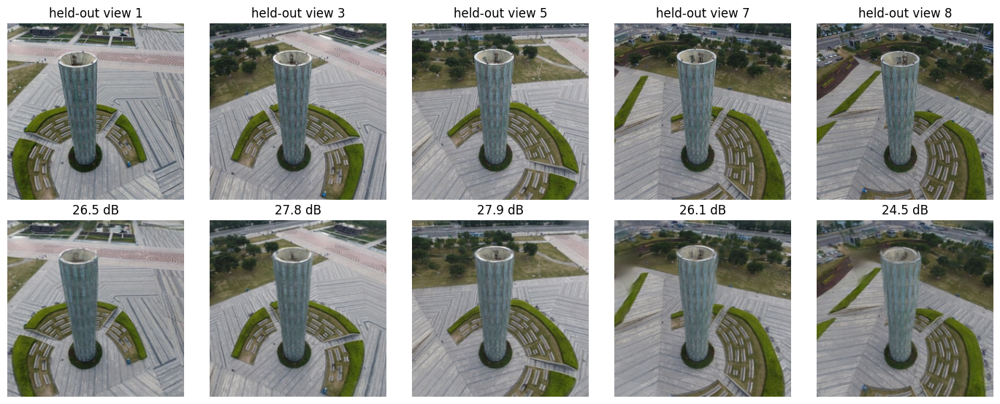

inputs [0, 2, 4, 6, 9]  targets [1, 3, 5, 7, 8]  mean held-out PSNR 26.55 dB


In [14]:
HOLDOUT_EXAMPLE = "example_4_blendedmvs_000107"
batch_h, result_h, _ = run_model(example_files(HOLDOUT_EXAMPLE), holdout=True)
tgt_idx = result_h.target_idx[0].tolist()
gt_h, rd_h = result_h.target_image[0].float().cpu(), result_h.render[0].float().cpu()
fig, axes = plt.subplots(2, len(tgt_idx), figsize=(2.8 * len(tgt_idx), 5.6))
for c, i in enumerate(tgt_idx):
    axes[0, c].imshow(gt_h[c].permute(1, 2, 0)); axes[0, c].set_title(f"held-out view {i}")
    axes[1, c].imshow(rd_h[c].clamp(0, 1).permute(1, 2, 0)); axes[1, c].set_title(f"{psnr(rd_h[c], gt_h[c]):.1f} dB")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"inputs {result_h.input_idx[0].tolist()}  targets {tgt_idx}  "
      f"mean held-out PSNR {np.mean([psnr(rd_h[c], gt_h[c]) for c in range(len(tgt_idx))]):.2f} dB")

# the held-out reconstruction in the viewer: only the 5 input views produced Gaussians
A_h = analyse(batch_h, result_h)
packed_h = gs_viewer.pack_splats(A_h["xyz"], A_h["sh"], A_h["opac_flat"], A_h["scale_flat"], A_h["quat"],
                                 view_ids=A_h["view_of_gaussian"], num_views=10, max_splats=MAX_SPLATS)
names = [f"view {i}" + (" (in)" if i in A_h["input_idx"] else " (held out)") for i in range(10)]
med_h = float(np.median(A_h["depth"]))
gs_viewer.show(packed_h, A_h["c2w"], A_h["fxfycxcy"], [med_h] * 10, cam_names=names,
               up=-A_h["c2w"][:, :3, 1].mean(0), title=f"{HOLDOUT_EXAMPLE} — held-out split",
               save_to=OUT_DIR / f"{HOLDOUT_EXAMPLE}_holdout_viewer.html")

In [28]:
# Run test on some of the images contained in /tmp/image_fish.zip
from zipfile import PyZipFile
file_name = "/mnt/projects/p3dcv/anycam/data/tartanair/ArchVizTinyHouseNight/Data_hard/image_lcam_fish.zip"
all_images = []
with PyZipFile(file_name) as zf:
    for name in zf.namelist():
        if Path(name).suffix.lower() in IMAGE_EXTS:
            all_images.append(zf.extract(name, path="/tmp"))

#print some stats
print(f"extracted {len(all_images)} images from {file_name}")


extracted 500 images from /mnt/projects/p3dcv/anycam/data/tartanair/ArchVizTinyHouseNight/Data_hard/image_lcam_fish.zip


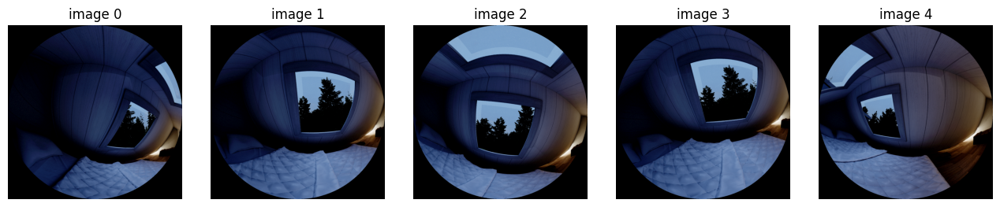

In [29]:

kept_images = all_images[:5]
# display the kept images
fig, axes = plt.subplots(1, len(kept_images), figsize=(2.6 * len(kept_images), 2.6))
for c, f in enumerate(kept_images):
    axes[c].imshow(plt.imread(f)); axes[c].set_title(f"image {c}")
    axes[c].axis("off")
plt.tight_layout(); plt.show()

In [25]:


# run model on the kept images
batch, result, dt = run_model(kept_images)
A = analyse(batch, result)
run_dir = OUT_DIR / EXAMPLE
run_dir.mkdir(parents=True, exist_ok=True)

print(f"{EXAMPLE}: {A['v_real']} views, forward pass {dt:.2f} s, "
      f"{A['xyz'].shape[0]:,} Gaussians from {len(A['input_idx'])} input views {A['input_idx'].tolist()}")
print("\npredicted intrinsics (pixels at 256 x 256) and horizontal FOV:")
for i, (fx, fy, cx, cy) in enumerate(A["fxfycxcy"] * engine.image_size):
    fov = np.degrees(2 * np.arctan(engine.image_size / (2 * fx)))
    print(f"  view {i}: fx {fx:6.1f}  fy {fy:6.1f}  cx {cx:6.1f}  cy {cy:6.1f}   FOV {fov:5.1f} deg")

example_0_dl3dv_000053: 5 views, forward pass 0.52 s, 327,680 Gaussians from 5 input views [0, 1, 2, 3, 4]

predicted intrinsics (pixels at 256 x 256) and horizontal FOV:
  view 0: fx  237.0  fy  237.0  cx  128.0  cy  128.0   FOV  56.7 deg
  view 1: fx  237.0  fy  237.0  cx  128.0  cy  128.0   FOV  56.7 deg
  view 2: fx  237.0  fy  237.0  cx  128.0  cy  128.0   FOV  56.7 deg
  view 3: fx  237.0  fy  237.0  cx  128.0  cy  128.0   FOV  56.7 deg
  view 4: fx  237.0  fy  237.0  cx  128.0  cy  128.0   FOV  56.7 deg


In [26]:
MAX_SPLATS = 100_000   # ~11 MB per viewer; raise for more detail
keep = A["keep"]
packed = gs_viewer.pack_splats(
    A["xyz"][keep], A["sh"][keep], A["opac_flat"][keep], A["scale_flat"][keep], A["quat"][keep],
    view_ids=A["view_of_gaussian"][keep], num_views=A["v_real"],
    min_opacity=0.02, max_splats=MAX_SPLATS,
)
# per camera: median depth of its Gaussians (orbit distance); views that are not inputs get the overall median
med = {int(A["input_idx"][k]): float(np.median(A["depth"][k])) for k in np.flatnonzero(A["real_input"])}
cam_depths = [med.get(i, float(np.median(list(med.values())))) for i in range(A["v_real"])]
up = -A["c2w"][:, :3, 1].mean(0)

print(f"{len(packed['splats']):,} of {int(keep.sum()):,} Gaussians shown")
gs_viewer.show(packed, A["c2w"], A["fxfycxcy"], cam_depths, up=up, title=EXAMPLE,
               save_to=run_dir / "gs_viewer.html")
print("standalone viewer:", run_dir / "gs_viewer.html")

63,686 of 327,680 Gaussians shown


standalone viewer: /mnt/home/colinmarmond/runs/notebook_examples/example_0_dl3dv_000053/gs_viewer.html
